# MNIST Test Dataset Visualization

This notebook loads and visualizes handwritten digit images from `mnist_train.csv` as **grayscale** images (28×28 pixels).


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Plot formatting
plt.rcParams['figure.dpi'] = 120


### 1. Load Data
`mnist_train.csv` has:
- **`label`**: Ground-truth digit class (0 to 9)
- **784 pixel columns** (`1x1`, `1x2`, ..., `28x28`): Grayscale pixel values ranging from 0 (white background / black) to 255.


In [2]:
# Locate dataset file path (works whether executing from src/ or project root)
csv_path = Path("../data/raw/mnist_train.csv")
if not csv_path.exists():
    csv_path = Path("data/raw/mnist_train.csv")

print(f"Loading data from: {csv_path.resolve()}")

# Load CSV
df = pd.read_csv(csv_path)

labels = df["label"].to_numpy()
pixels = df.drop(columns=["label"]).to_numpy()

print(f"Total samples: {len(df):,}")
print(f"Pixels matrix shape: {pixels.shape} (values range {pixels.min()} to {pixels.max()})")
print("\nClass distribution:")
print(df["label"].value_counts().sort_index().to_string())


Loading data from: D:\Dev\Python\num-classify\data\raw\mnist_train.csv
Total samples: 60,000
Pixels matrix shape: (60000, 784) (values range 0 to 255)

Class distribution:
label
0    5923
1    6742
2    5958
3    6131
4    5842
5    5421
6    5918
7    6265
8    5851
9    5949


### 2. Visualize a Single Digit as Grayscale Image
Each 784-element row is reshaped into a 28×28 2D array and displayed using `cmap='gray'`.


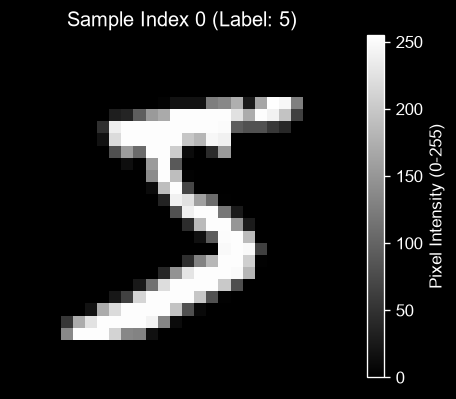

In [3]:
sample_idx = 0
image = pixels[sample_idx].reshape(28, 28)
label = labels[sample_idx]

plt.figure(figsize=(4, 4))
plt.imshow(image, cmap="gray")
plt.title(f"Sample Index {sample_idx} (Label: {label})", fontsize=12)
plt.axis("off")
plt.colorbar(label="Pixel Intensity (0-255)", fraction=0.046, pad=0.04)
plt.show()


### 3. Grid of Sample Digits
Display a 5×5 grid of sequential test samples.


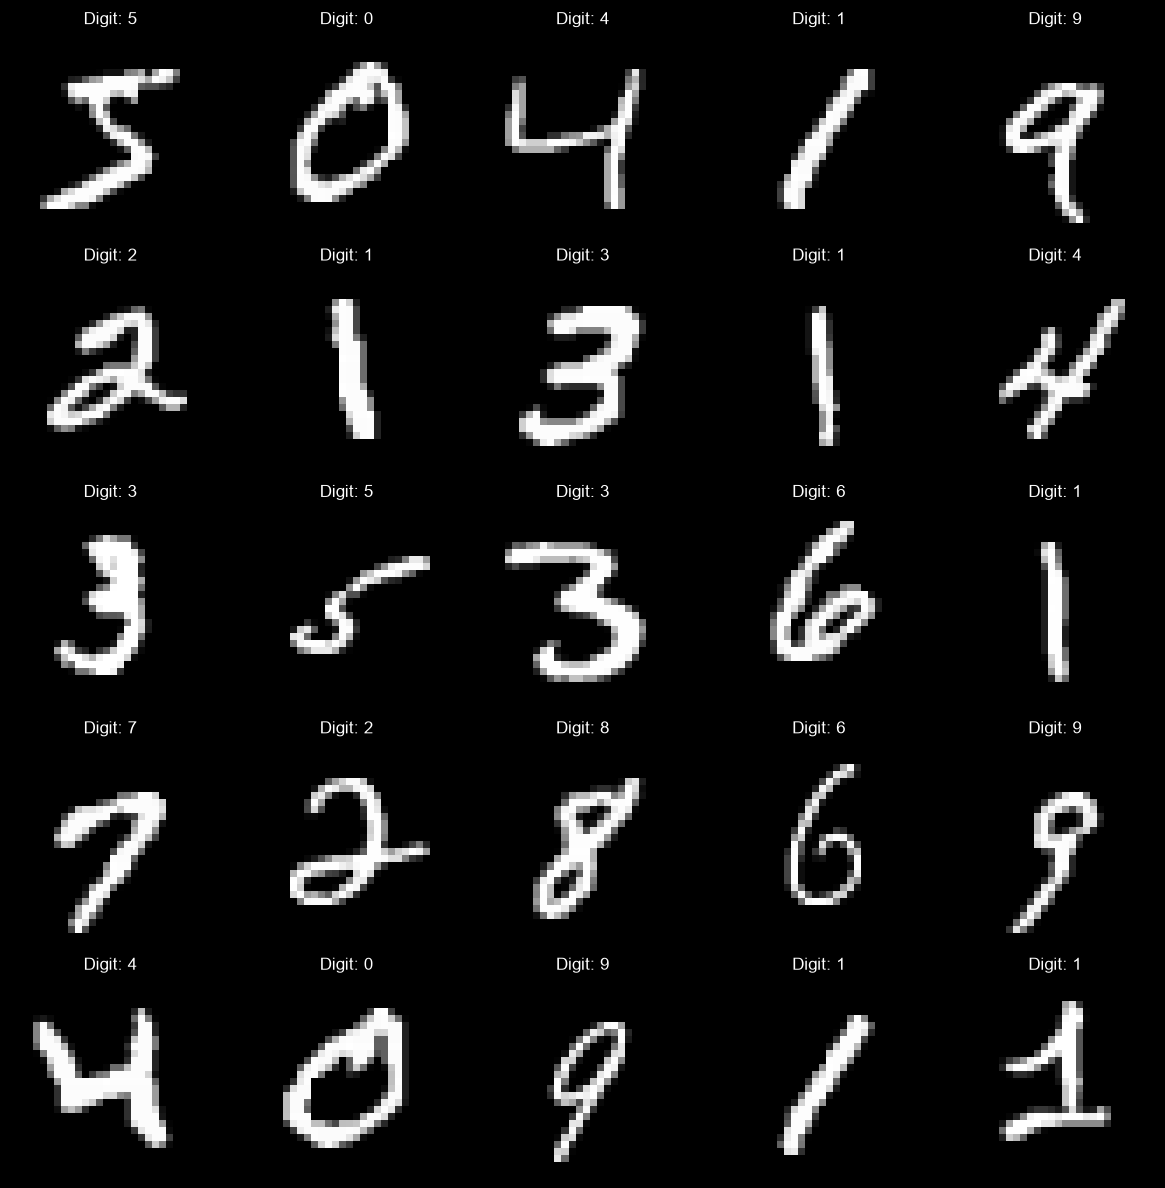

In [4]:
def plot_digit_grid(pixel_data, label_data, rows=5, cols=5, start_idx=0):
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2, rows * 2))
    for i, ax in enumerate(axes.flat):
        idx = start_idx + i
        if idx < len(pixel_data):
            img = pixel_data[idx].reshape(28, 28)
            ax.imshow(img, cmap="gray")
            ax.set_title(f"Digit: {label_data[idx]}", fontsize=10)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

plot_digit_grid(pixels, labels, rows=5, cols=5, start_idx=0)


### 4. Sample Digit for Each Class (0 to 9)
Show one example for each digit class side-by-side.


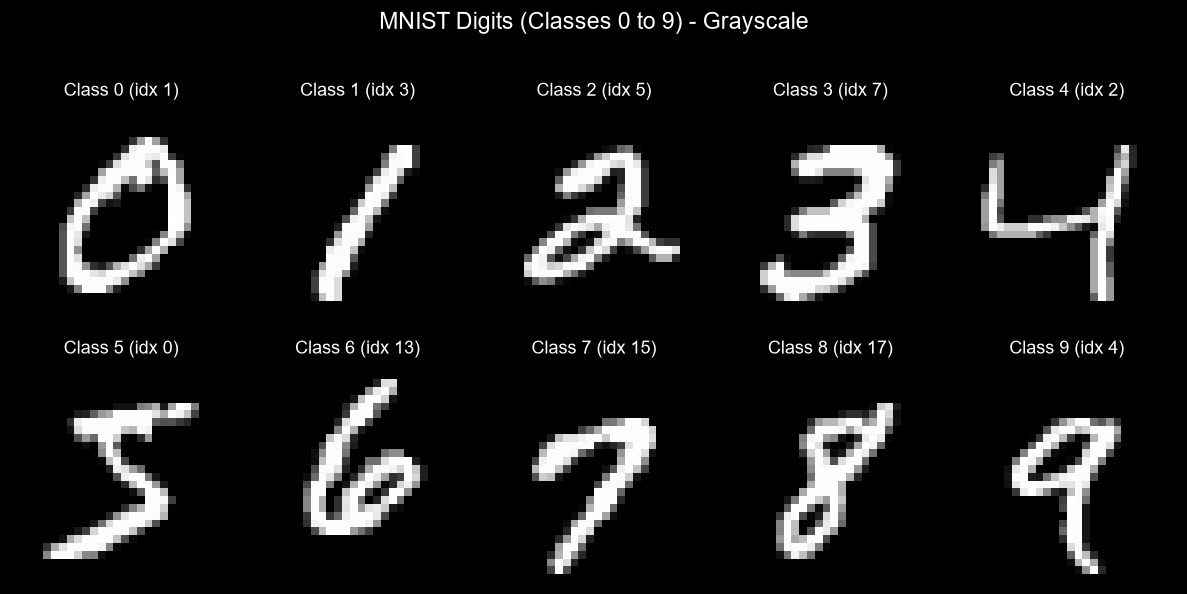

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for digit in range(10):
    ax = axes[digit // 5, digit % 5]
    match_indices = np.where(labels == digit)[0]
    first_idx = match_indices[0]
    img = pixels[first_idx].reshape(28, 28)
    
    ax.imshow(img, cmap="gray")
    ax.set_title(f"Class {digit} (idx {first_idx})", fontsize=11)
    ax.axis("off")

plt.suptitle("MNIST Digits (Classes 0 to 9) - Grayscale", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()
